# Breast Cancer EDA

**Purpose:** Explore the scikit-learn Breast Cancer Wisconsin dataset to understand its structure, class balance, feature distributions and correlations before building any models.

## 1. Setup

In [17]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## 2. Load the data

The dataset is loaded as a pandas DataFrame. `df` holds the 30 features plus the `target` column.

In [18]:
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

## 3. Data structure

Shape, data types and missing values.

In [19]:
print(df.shape)
print(cancer.feature_names[:5])
print(cancer.target_names)
print(df.isnull().sum())
df.info()

(569, 31)
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
['malignant' 'benign']
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target            

**Observations:**
- 569 rows and 31 columns: 30 features plus `target`.
- All 30 features are numeric (float64), and `target` is an integer (0/1).
- There are no missing values in any column, so no cleaning is needed.
- The 30 features are 10 measurements of the cell nuclei (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension). Each is recorded three ways: **mean**, **error** (standard error) and **worst** (the largest value).

## 4. Target variable

Map 0/1 to readable labels, then count each class.

In [20]:
print(df['target'].unique())
df['diagnosis'] = df['target'].map({0: 'malignant', 1: 'benign'})
print(df[['target', 'diagnosis']].groupby('diagnosis').head(3))

counts = df['diagnosis'].value_counts()
percentages = (df['diagnosis'].value_counts(normalize=True) * 100).round(2)
summary_df = pd.DataFrame({'counts': counts, 'percentages': percentages})
print(summary_df)

[0 1]
    target  diagnosis
0        0  malignant
1        0  malignant
2        0  malignant
19       1     benign
20       1     benign
21       1     benign
           counts  percentages
diagnosis                     
benign        357        62.74
malignant     212        37.26


**Observations:**
- Encoding: 0 = malignant and 1 = benign. Note that sklearn treats benign as the "positive" class (1). Keep this in mind when reading precision and recall later.
- Benign: 357 (62.7%). Malignant: 212 (37.3%).
- **Verdict:** the classes are mildly imbalanced, not severely enough to need resampling.
- **For modeling later:** keep the same 63/37 ratio when splitting into train and test sets, and look at recall on malignant cases, not just accuracy. Missing a real cancer (a false negative) is much worse than a false alarm.

## 5. Summary statistics


In [21]:
readable_summary = df[cancer.feature_names].describe().T.round(4).sort_values(by='mean', ascending=False)
readable_summary

,count,mean,std,min,25%,50%,75%,max
worst area,569.0,880.5831,569.3570,185.2000,515.3000,686.5000,1084.0000,4254.0000
mean area,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
worst perimeter,569.0,107.2612,33.6025,50.4100,84.1100,97.6600,125.4000,251.2000
mean perimeter,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area error,569.0,40.3371,45.4910,6.8020,17.8500,24.5300,45.1900,542.2000
worst texture,569.0,25.6772,6.1463,12.0200,21.0800,25.4100,29.7200,49.5400
mean texture,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
worst radius,569.0,16.2692,4.8332,7.9300,13.0100,14.9700,18.7900,36.0400
mean radius,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
perimeter error,569.0,2.8661,2.0219,0.7570,1.6060,2.2870,3.3570,21.9800


**Observations:**
- **Largest scale:** `worst area` (max 4254) and `mean area` (max 2501) are by far the biggest features. Area grows with the square of the radius, so it's naturally much larger than the other measurements.
- **Smallest scale:** `fractal dimension error` (max ≈ 0.03, mean ≈ 0.004) is the smallest feature.
- **Ratio:** the largest max is about **140,000 times** the smallest max. The features are on extremely different scales.
- **Skew:** for every feature the mean is higher than the median, so all 30 features are right-skewed: most values are moderate, and a few very large values pull the mean up.
  - `worst area`: mean 880.6 vs median 686.5, so the mean is about 28% higher.
  - `area error` is the most skewed: mean 40.3 vs median 24.5, about 65% higher.
  - The "error" features are generally the most skewed group.
  - The large values are probably the bigger malignant tumors. I'll check this in step 6 (histograms) and step 8 (box plots). Skewed features may also benefit from a log transform before modeling.
- **Zeros:** the six concavity and concave points features have a minimum of exactly 0. I'll check these in step 8.
- **Why it matters:** models that use distances (like k-NN or SVM) or gradient descent would be dominated by the area features, and the small-scale features would barely count. **The features must be scaled before modeling**, for example standardized to mean 0 and standard deviation 1.

## 6. Distributions by diagnosis


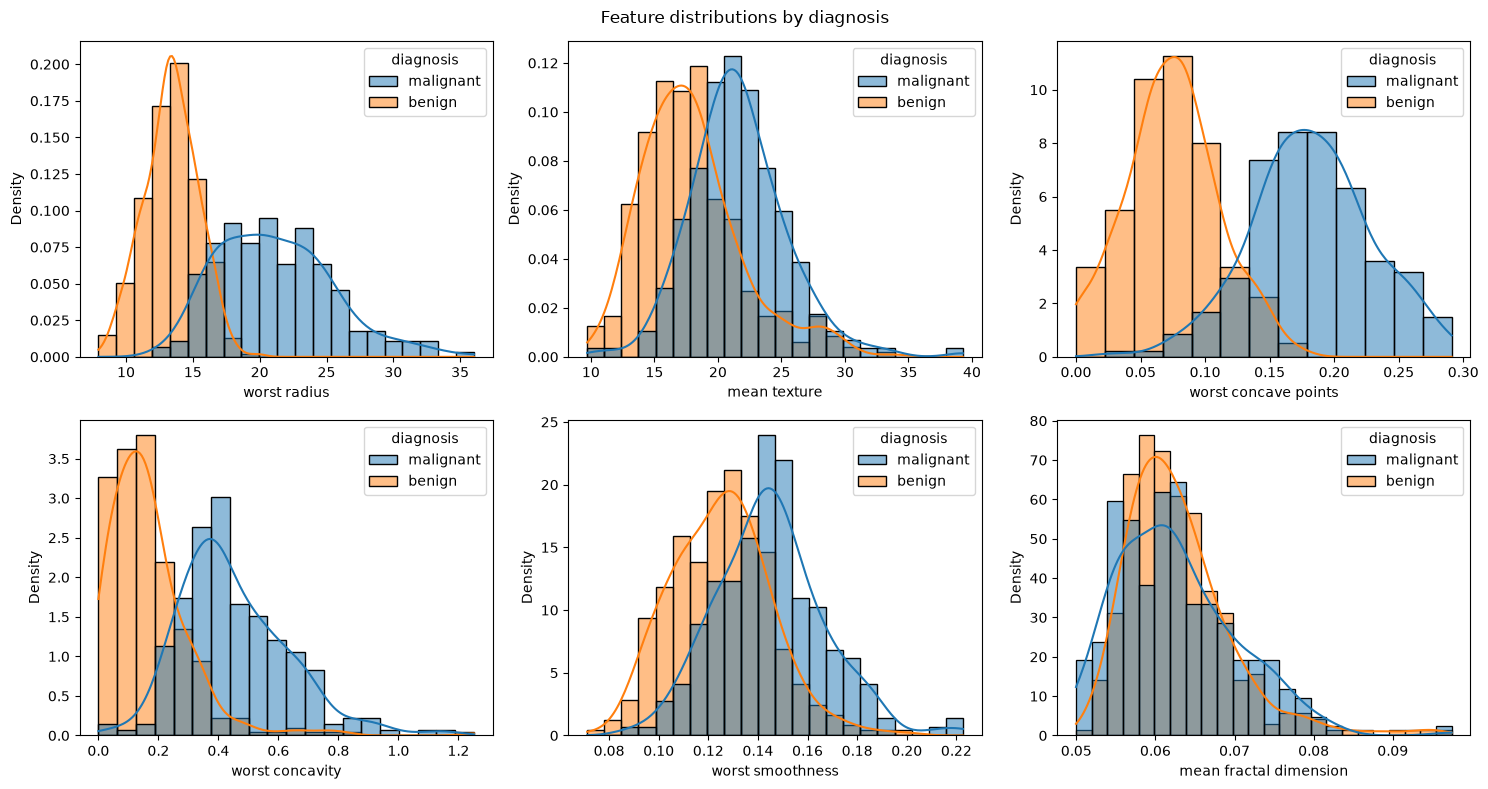

In [22]:
features = ['worst radius', 'mean texture', 'worst concave points', 'worst concavity','worst smoothness','mean fractal dimension']
fig,axes = plt.subplots(2,3, figsize=(15,8))
axes=axes.flatten()

for feature,ax in zip(features,axes):
    sns.histplot(data=df, x=feature, hue='diagnosis',hue_order=['malignant','benign'], kde=True, stat='density', common_norm=False,ax=ax)

fig.suptitle('Feature distributions by diagnosis')
plt.tight_layout()
plt.show()

**Observations:**
- **Ranking (clearest separation → most overlap):** `worst concave points` > `worst radius` > `worst concavity` > `mean texture` ≈ `worst smoothness` > `mean fractal dimension`.
- **Best separator:** `worst concave points`. Benign peaks around 0.07 and malignant around 0.17, and they only overlap between about 0.10 and 0.15.
- **Direction:** in every feature that separates, malignant has the higher values. Malignant tumors have bigger cells (`worst radius`) and more irregular outlines: more dents (`worst concave points`) and deeper ones (`worst concavity`).
- **Middle cases:** `mean texture` (benign ≈ 17, malignant ≈ 21) and `worst smoothness` (benign ≈ 0.125, malignant ≈ 0.145). Malignant is shifted to the right, but the overlap is heavy, so neither can separate the classes alone.
- **No separation:** `mean fractal dimension`. Both classes peak around 0.06 and the distributions almost completely overlap, as I predicted.
- **Zeros:** `worst concavity` and `worst concave points` have a spike of benign tumors at exactly 0. These are the 13 tumors from step 5 with perfectly smooth outlines. That's plausible for benign cells, but it could also be a measurement issue, so I'll check it in step 8.
- **For modeling:** the size and concavity features, especially `worst concave points` and `worst radius`, look like the strongest predictors. `mean fractal dimension` adds little on its own.

## 7. Correlations

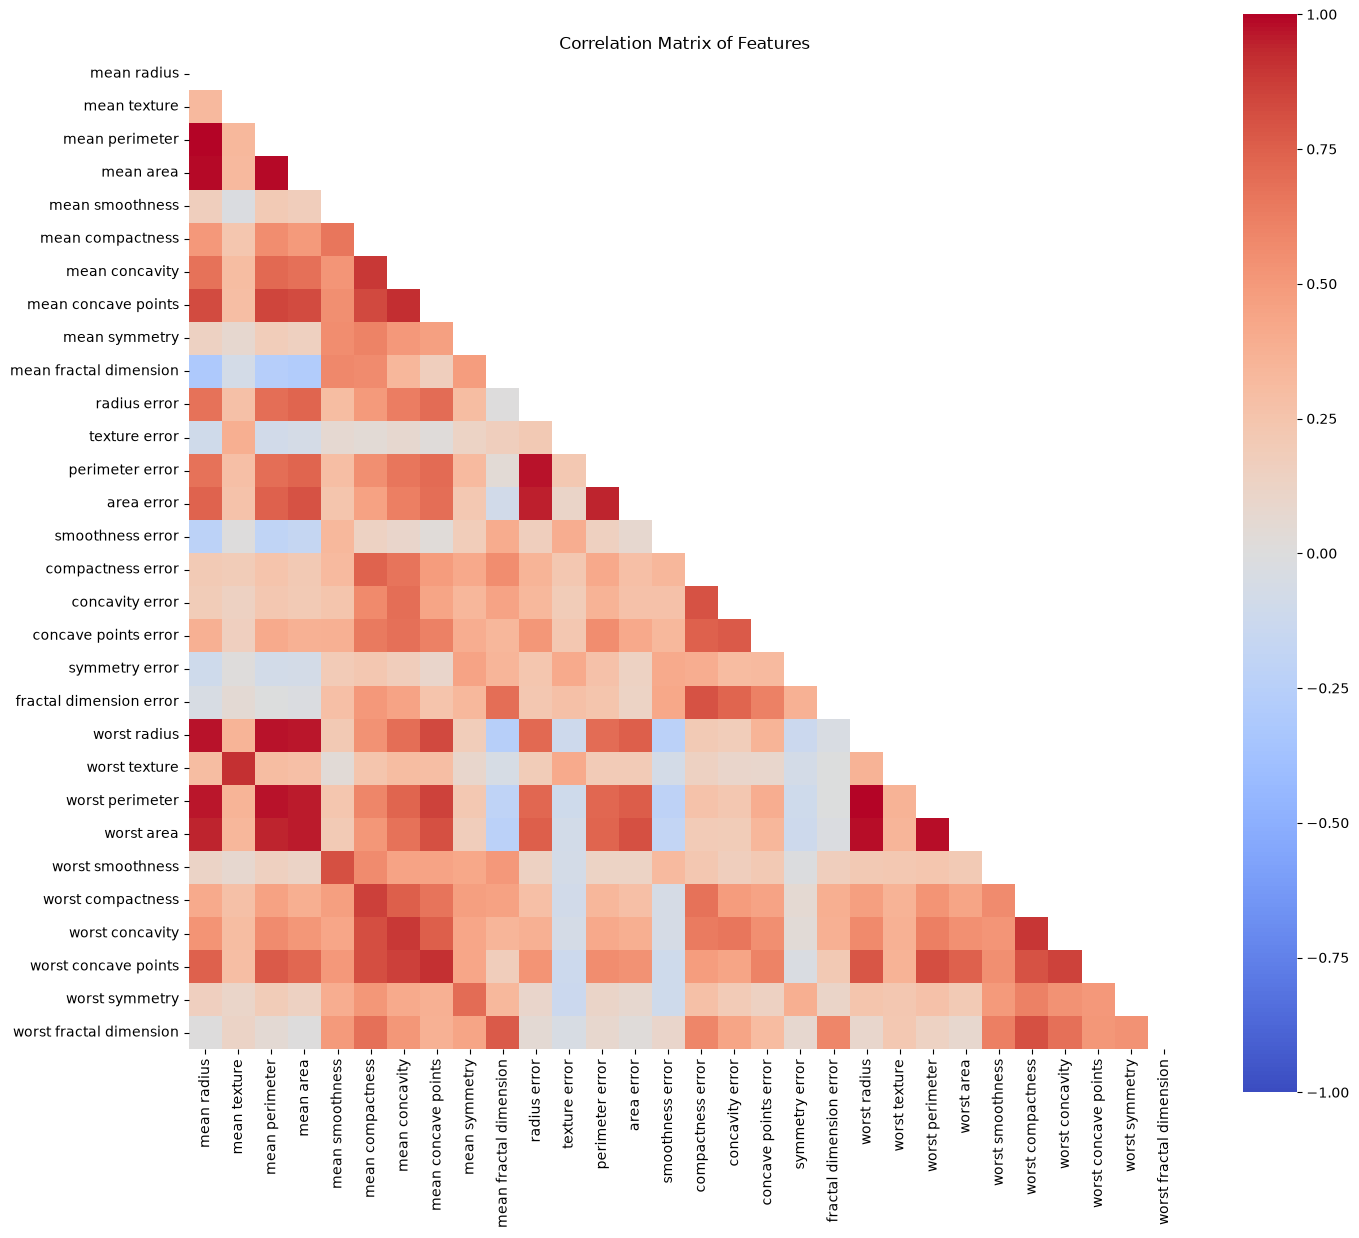

In [36]:
corr=df[cancer.feature_names].corr()
plt.figure(figsize=(16,14))
uppermask =np.triu(np.ones(corr.shape)).astype(bool)
sns.heatmap(corr, vmin=-1, vmax=1,center=0, cmap='coolwarm', square=True, mask = uppermask)
plt.title('Correlation Matrix of Features')
plt.show()

Pairs of features with |r| > 0.9 (each pair listed once):

In [35]:
mask = np.tril(np.ones(corr.shape), k=-1).astype(bool)
pairs= corr.where(mask).stack()
high = pairs[ pairs.abs() > 0.9].round(3)
high = high.sort_values(ascending=False)
high

mean perimeter        mean radius            0.998
worst perimeter       worst radius           0.994
mean area             mean radius            0.987
                      mean perimeter         0.987
worst area            worst radius           0.984
                      worst perimeter        0.978
perimeter error       radius error           0.973
worst perimeter       mean perimeter         0.970
worst radius          mean radius            0.970
                      mean perimeter         0.969
worst perimeter       mean radius            0.965
worst radius          mean area              0.963
worst area            mean area              0.959
worst perimeter       mean area              0.959
area error            radius error           0.952
worst area            mean perimeter         0.942
                      mean radius            0.941
area error            perimeter error        0.938
mean concave points   mean concavity         0.921
worst texture         mean text

**Observations:**
- **21 pairs** of features are almost perfectly correlated (|r| > 0.9).
- **Group 1: size (18 of the 21 pairs).** Radius, perimeter and area are all near-perfectly correlated. All 15 possible pairs among the 6 mean and worst size features are above 0.9, both within the mean and worst versions and across them (for example `mean radius` and `worst radius`: 0.970). Together they form one big block in the heatmap.
  - **Why:** all three come from the same cell outline. Perimeter ≈ 2π × radius, so it moves in a straight line with radius (r = 0.998). Area ≈ π × radius² grows along a curve, and correlation measures straight-line relationships, so radius vs area is slightly lower (0.987).
  - **Why mean and worst match:** they describe the same tumor's cells. If the cells are large on average, the largest ones are large too.
- **Group 2: size "error" features (the other 3 size pairs).** `radius error`, `perimeter error` and `area error` correlate strongly with each other (0.94–0.97), but not above 0.9 with the mean or worst size features (at most about 0.81). "Error" measures how much the size *varies* within an image, which is a different thing from the size itself.
- **Group 3: shape and texture (the last 3 pairs).**
  - `mean concavity` and `mean concave points` (0.921): both describe the dents in the cell outline. Cells with *deeper* dents also tend to have *more* of them.
  - `mean texture` / `worst texture` (0.912) and `mean concave points` / `worst concave points` (0.910): the same mean-vs-worst effect as for size.
  - Compactness, concavity and concave points form a weaker block in the heatmap (about 0.80–0.89).
- **No strong negatives:** the most negative correlation is only about −0.31 (`mean fractal dimension` vs `mean radius`). All the strong relationships are positive.
- **For modeling:** many features are redundant. The 6 mean and worst size features carry roughly *one* piece of information: overall size. Keeping only one of them (for example `worst radius`) loses very little. For linear models like logistic regression, redundant features can make the model unstable, so keep one feature per group or use regularization or PCA. Tree-based models are less affected.